# CUPED

Снижение дисперсии метрики A/B-теста с помощью `x_pre` — активности пользователя до эксперимента. Данные синтетические, истинный эффект 0.25.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import sqrt
from scipy import stats

pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'axes.axisbelow': True})

In [2]:
def generate_experiment(seed=123):
    rng = np.random.default_rng(seed)

    n_per_group = 8_000
    n = 2 * n_per_group
    variant = np.array(['control'] * n_per_group + ['treatment'] * n_per_group)
    is_treatment = (variant == 'treatment').astype(int)

    x_pre = rng.lognormal(mean=1.8, sigma=0.75, size=n)

    post_activity = 0.8 * x_pre + 0.6 * is_treatment + rng.normal(0, 1.0, size=n)

    noise = rng.normal(0, 3.5, size=n)
    true_effect = 0.25
    y = 3.0 + 0.65 * x_pre + true_effect * is_treatment + noise

    return pd.DataFrame({
        'user_id': np.arange(1, n + 1),
        'variant': variant,
        'x_pre': x_pre,
        'post_activity': post_activity,
        'y': y,
    })


exp = generate_experiment(seed=123)
exp.head()

,user_id,variant,x_pre,post_activity,y
0,1,control,2.8811,2.0255,5.6940
1,2,control,4.5913,2.3807,-0.0582
2,3,control,15.8940,12.0618,7.2889
3,4,control,6.9970,7.3537,11.0596
4,5,control,12.0634,8.4098,4.6427


## 1. Коэффициент $\theta$

$$\theta = \frac{\operatorname{Cov}(Y, X)}{\operatorname{Var}(X)}$$

`x_centered` и `y_centered` — центрированные `x_pre` и `y`. Через них вручную считаются `cov_y_x` и `var_x`, без `np.cov`.

In [3]:
x_centered = exp['x_pre'] - exp['x_pre'].mean()
y_centered = exp['y'] - exp['y'].mean()

cov_y_x = (x_centered * y_centered).sum() / (len(exp) - 1)
var_x = (x_centered ** 2).sum() / (len(exp) - 1)

theta = cov_y_x / var_x
print(f'theta = {theta:.4f}')

theta = 0.6437


## 2. CUPED-метрика

$$Y_{\mathrm{CUPED}} = Y - \theta\,(X - \bar{X})$$

`y_cuped` — метрика без той части, которую объясняет `x_pre`. Среднее не меняется, потому что `x_centered` центрирован.

In [4]:
y_cuped = exp['y'] - theta * x_centered

pd.DataFrame({'mean': [exp['y'].mean(), y_cuped.mean()],
              'variance': [exp['y'].var(), y_cuped.var()]}, index=['y', 'y_cuped'])

,mean,variance
y,8.3596,31.8281
y_cuped,8.3596,12.1996


## 3. Эффект и стандартная ошибка

$$\hat\tau = \bar{Y}_T - \bar{Y}_C, \qquad \operatorname{SE} = \sqrt{\frac{s_T^2}{n_T} + \frac{s_C^2}{n_C}}$$

`baseline_effect` и `baseline_se` считаются по `y`, `cuped_effect` и `cuped_se` — по `y_cuped`. Дисперсия каждой группы делится на размер своей группы (`n_t`, `n_c` = 8 000), а не на общий `n`.

In [5]:
work = exp.copy()
work['y_cuped'] = y_cuped

control_y = work.loc[work['variant'] == 'control', 'y']
treatment_y = work.loc[work['variant'] == 'treatment', 'y']
n_c, n_t = len(control_y), len(treatment_y)
baseline_effect = treatment_y.mean() - control_y.mean()

var_control = control_y.var(ddof=1)
var_treatment = treatment_y.var(ddof=1)
baseline_se = sqrt(var_treatment / n_t + var_control / n_c)

control_cuped = work.loc[work['variant'] == 'control', 'y_cuped']
treatment_cuped = work.loc[work['variant'] == 'treatment', 'y_cuped']
cuped_effect = treatment_cuped.mean() - control_cuped.mean()
cuped_var_control = control_cuped.var(ddof=1)
cuped_var_treatment = treatment_cuped.var(ddof=1)
cuped_se = sqrt(cuped_var_treatment / n_t + cuped_var_control / n_c)

pd.DataFrame({
    'estimate': [baseline_effect, cuped_effect],
    'standard_error': [baseline_se, cuped_se]
}, index=['baseline', 'cuped'])

,estimate,standard_error
baseline,0.3001,0.0892
cuped,0.2556,0.0552


## 4. Почему `post_activity` нельзя брать ковариатой

`post_activity` измерена после старта эксперимента и зависит от treatment. Сравним разницу между группами для `x_pre` и `post_activity` и посчитаем CUPED с `post_activity`.

In [6]:
is_t = work['variant'] == 'treatment'
x_pre_diff = work.loc[is_t, 'x_pre'].mean() - work.loc[~is_t, 'x_pre'].mean()
post_diff = work.loc[is_t, 'post_activity'].mean() - work.loc[~is_t, 'post_activity'].mean()

post_centered = work['post_activity'] - work['post_activity'].mean()
theta_post = (post_centered * y_centered).sum() / (post_centered ** 2).sum()
y_cuped_post = work['y'] - theta_post * post_centered
post_effect = y_cuped_post[is_t].mean() - y_cuped_post[~is_t].mean()

pd.Series({
    'x_pre_diff (T − C)': x_pre_diff,
    'post_diff (T − C)': post_diff,
    'theta_post': theta_post,
    'theta_post × post_diff': theta_post * post_diff,
    'post_effect': post_effect,
    'true_effect': 0.25,
}).to_frame('value')

,value
x_pre_diff (T − C),0.0691
post_diff (T − C),0.6714
theta_post,0.7799
theta_post × post_diff,0.5236
post_effect,-0.2236
true_effect,0.2500


У `x_pre` разница между группами случайная (0.07), у `post_activity` систематическая (0.67), потому что её увеличивает treatment. CUPED вычитает из эффекта `theta_post × post_diff` ≈ 0.52, а это больше всего эффекта. Оценка становится −0.22 при истинном +0.25.

## 5. Корреляция и снижение дисперсии

`rho` — корреляция `x_pre` и `y`. `predicted_reduction = rho²` — ожидаемое снижение дисперсии, `actual_reduction` — фактическое. `sample_size_ratio` показывает, во сколько раз меньше пользователей нужно CUPED для той же SE.

In [7]:
rho = work['x_pre'].corr(work['y'])
predicted_reduction = rho ** 2
actual_reduction = 1 - work['y_cuped'].var(ddof=1) / work['y'].var(ddof=1)
se_reduction = 1 - cuped_se / baseline_se
sample_size_ratio = (baseline_se / cuped_se) ** 2

pd.Series({
    'rho': rho,
    'predicted_reduction': predicted_reduction,
    'actual_reduction': actual_reduction,
    'se_reduction': se_reduction,
    'sample_size_ratio': sample_size_ratio,
}).to_frame('value')

,value
rho,0.7853
predicted_reduction,0.6167
actual_reduction,0.6167
se_reduction,0.3811
sample_size_ratio,2.6106


## 6. Итоговый отчёт

95% ДИ: `estimate ± 1.96 · standard_error`, p-value по нормальному приближению.

In [8]:
report = pd.DataFrame({
    'estimate': [baseline_effect, cuped_effect],
    'standard_error': [baseline_se, cuped_se],
    'ci_left_95': [baseline_effect - 1.96 * baseline_se, cuped_effect - 1.96 * cuped_se],
    'ci_right_95': [baseline_effect + 1.96 * baseline_se, cuped_effect + 1.96 * cuped_se],
}, index=['baseline', 'cuped'])
report['p_value'] = 2 * stats.norm.sf(np.abs(report['estimate'] / report['standard_error']))

report

,estimate,standard_error,ci_left_95,ci_right_95,p_value
baseline,0.3001,0.0892,0.1253,0.4748,0.0008
cuped,0.2556,0.0552,0.1474,0.3637,0.0000


## 7. Проверка симуляцией

500 повторов эксперимента с разными сидами. `power` — доля значимых результатов при α = 0.05, `coverage` — доля 95% ДИ, которые содержат истинный эффект 0.25.

In [9]:
def estimate(data, metric):
    t = data.loc[data['variant'] == 'treatment', metric]
    c = data.loc[data['variant'] == 'control', metric]
    return t.mean() - c.mean(), sqrt(t.var(ddof=1) / len(t) + c.var(ddof=1) / len(c))


rows = []
for seed in range(500):
    d = generate_experiment(seed)
    x_c = d['x_pre'] - d['x_pre'].mean()
    d['y_cuped'] = d['y'] - (x_c * (d['y'] - d['y'].mean())).sum() / (x_c ** 2).sum() * x_c
    for method, metric in [('baseline', 'y'), ('cuped', 'y_cuped')]:
        effect, se = estimate(d, metric)
        rows.append({'method': method, 'effect': effect, 'se': se})

sim = pd.DataFrame(rows)
sim['significant'] = (sim['effect'] / sim['se']).abs() > 1.96
sim['covers'] = (sim['effect'] - 1.96 * sim['se'] <= 0.25) & (0.25 <= sim['effect'] + 1.96 * sim['se'])

sim.groupby('method').agg(
    mean_effect=('effect', 'mean'),
    sd_effect=('effect', 'std'),
    power=('significant', 'mean'),
    coverage=('covers', 'mean'),
)

,mean_effect,sd_effect,power,coverage
method,,,,
baseline,0.2517,0.0920,0.7880,0.9500
cuped,0.2517,0.0562,0.9960,0.9400


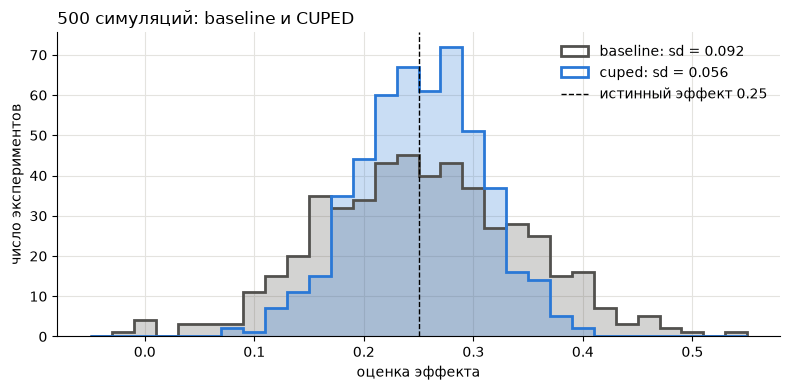

In [10]:
bins = np.linspace(-0.05, 0.55, 31)
fig, ax = plt.subplots(figsize=(8, 4))
for method, color in [('baseline', '#52514e'), ('cuped', '#2a78d6')]:
    est = sim.loc[sim['method'] == method, 'effect']
    ax.hist(est, bins=bins, color=color, alpha=0.25)
    ax.hist(est, bins=bins, color=color, histtype='step', lw=2, label=f'{method}: sd = {est.std():.3f}')
ax.axvline(0.25, color='black', ls='--', lw=1, label='истинный эффект 0.25')
ax.set_xlabel('оценка эффекта')
ax.set_ylabel('число экспериментов')
ax.set_title('500 симуляций: baseline и CUPED', loc='left')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig('../images/cuped_simulation.png', dpi=150, bbox_inches='tight')
plt.show()

## Что сделано

- Вручную посчитаны `theta` и CUPED-метрика `y_cuped`.
- Для baseline и CUPED посчитаны эффект, SE, 95% ДИ и p-value. SE снизилась с 0.089 до 0.055 (−38%), дисперсия — на 62%, что совпадает с `rho² = 0.617`. Для той же точности нужно в 2.6 раза меньше пользователей.
- На цифрах показано, почему `post_activity` не подходит в ковариаты: с ней оценка −0.22 при истинном 0.25.
- В 500 симуляциях мощность выросла с 79% до 99.6%, покрытие 95% ДИ около 95%.